# Target triage: the agent, its checks and the ranking

Displays the results of `python -m agetarget assess` for the latest batch of agent runs (`results/targets/`). The full assessments are in `results/targets/report.md`; the write-up is `docs/2-target-triage.md`.

In [1]:
import json

import pandas as pd
from IPython.display import Image, Markdown, display

from agetarget import config as cfg

pd.set_option("display.precision", 3)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 90)

from agetarget.targets import agent, checks, evidence
from agetarget.targets.pipeline import batches, load_dossiers, mean_scores
from agetarget.targets.rubric import DIMENSIONS, WEIGHTS

T = cfg.TARGET_RESULTS
print("Latest batch:", batches()[-1].name, "| weights:", WEIGHTS)

Latest batch: 20261117-094506 | weights: {'ageing_relevance': 0.3, 'mechanism': 0.15, 'tractability': 0.2, 'safety': 0.2, 'clinical_precedence': 0.15}


## 1. The evidence

Gathered without an LLM from Open Targets, UniProt and Europe PMC, cached in `results/targets/evidence/`. The share of each protein's papers on ageing or senescence measures relevance; raw counts would measure popularity.

In [2]:
facts = {s: evidence.facts(d) for s, d in load_dossiers().items()}
pd.DataFrame({s: {
    "protein": f["uniprot.protein_name"],
    "tractable modalities": ", ".join(m.replace("_", " ") for m in ("small_molecule", "antibody", "protac", "other_modality")
                                      if f[f"tractability.{m}"]) or "none",
    "safety liabilities": f["safety.n_liabilities"],
    "max clinical stage": f["clinical.max_stage_label"],
    "age-related disease links": f["associations.n_ageing"],
    "papers": f["literature.any"],
    "ageing share": f["literature.ageing_share"],
    "senescence share": f["literature.senescence_share"],
    "MR": f["causal.mr_status"].split(":")[0],
} for s, f in facts.items()}).T

,protein,tractable modalities,safety liabilities,max clinical stage,age-related disease links,papers,ageing share,senescence share,MR
ADM,Pro-adrenomedullin,"small molecule, antibody, protac",0,PHASE_2_3,11,11792,0.177,0.078,tested
B2M,Beta-2-microglobulin,"small molecule, antibody, protac",0,none,0,29796,0.102,0.05,not tested
CST3,Cystatin-C,"small molecule, antibody, protac",0,none,18,30232,0.246,0.055,tested
SERPINE1,Plasminogen activator inhibitor 1,"small molecule, antibody, protac",2,PHASE_1,7,59619,0.208,0.122,tested
GDF15,Growth/differentiation factor 15,"antibody, protac",0,none,12,16852,0.347,0.195,tested
LEP,Leptin,antibody,2,none,8,143292,0.231,0.094,tested
TIMP1,Metalloproteinase inhibitor 1,"antibody, protac",2,none,10,46110,0.211,0.12,not tested


## 2. Did the runs work, and are the citations real?

Every value the agent cites is compared with the evidence it was shown in that run. *Mismatch* or *unknown fact* would be a hallucination.

In [3]:
runs = pd.read_csv(T / "run_summary.csv")
display(runs.groupby("target")[["completed", "turns", "tool_coverage", "background_claims", "conflicts_flagged"]].mean().round(2))
citations = pd.read_csv(T / "citations.csv")
print(citations.status.value_counts().to_string())
citations[citations.status != "match"]

,completed,turns,tool_coverage,background_claims,conflicts_flagged
target,,,,,
ADM,1.0,2.00,1.0,4.33,2.00
B2M,1.0,2.00,1.0,2.67,2.00
CST3,1.0,2.33,1.0,2.33,2.00
GDF15,1.0,2.67,1.0,4.00,2.33
LEP,1.0,2.00,1.0,4.00,2.33
SERPINE1,1.0,2.67,1.0,1.67,2.00
TIMP1,1.0,2.00,1.0,2.00,1.33


status
match       264
mismatch      1


,target,run,dimension,fact_id,cited,actual,status,changed_since_run
175,LEP,2,mechanism,causal.mr_results,"parental_longevity b = +0.045 (p = 0.14), frailty b = +0.050 (p = 0.26), grimage_accel...","['parental_longevity: Wald ratio, 1 variant(s), b = +0.045 (SE 0.030), p = 0.14, Bonfe...",mismatch,False


## 3. Ranking

Overall score = weighted sum of the five dimension scores, computed in code. The rule-based baseline applies fixed rules to the same evidence.

,agent_overall,agent_min,agent_max,baseline_overall,recommendation,recommendation_counts,agent_rank,baseline_rank
SERPINE1,3.37,3.30,3.50,3.50,prioritise,"prioritise 2, consider 1",1,2
ADM,3.20,3.05,3.35,4.00,consider,consider 3,2,1
GDF15,2.70,2.70,2.70,3.45,consider,consider 3,3,3
B2M,2.58,2.35,2.70,2.30,consider,consider 3,4,7
TIMP1,2.30,2.30,2.30,2.95,deprioritise,"deprioritise 2, consider 1",5,5
CST3,2.25,2.25,2.25,3.35,deprioritise,deprioritise 3,6,4
LEP,1.95,1.85,2.00,2.95,deprioritise,deprioritise 3,7,5


Agent vs baseline, per dimension:


,spearman_rho,mean_abs_diff
dimension,,
ageing_relevance,0.00,1.43
mechanism,0.21,1.00
tractability,0.90,0.14
safety,0.91,1.00
clinical_precedence,1.00,0.10
overall,0.68,0.67


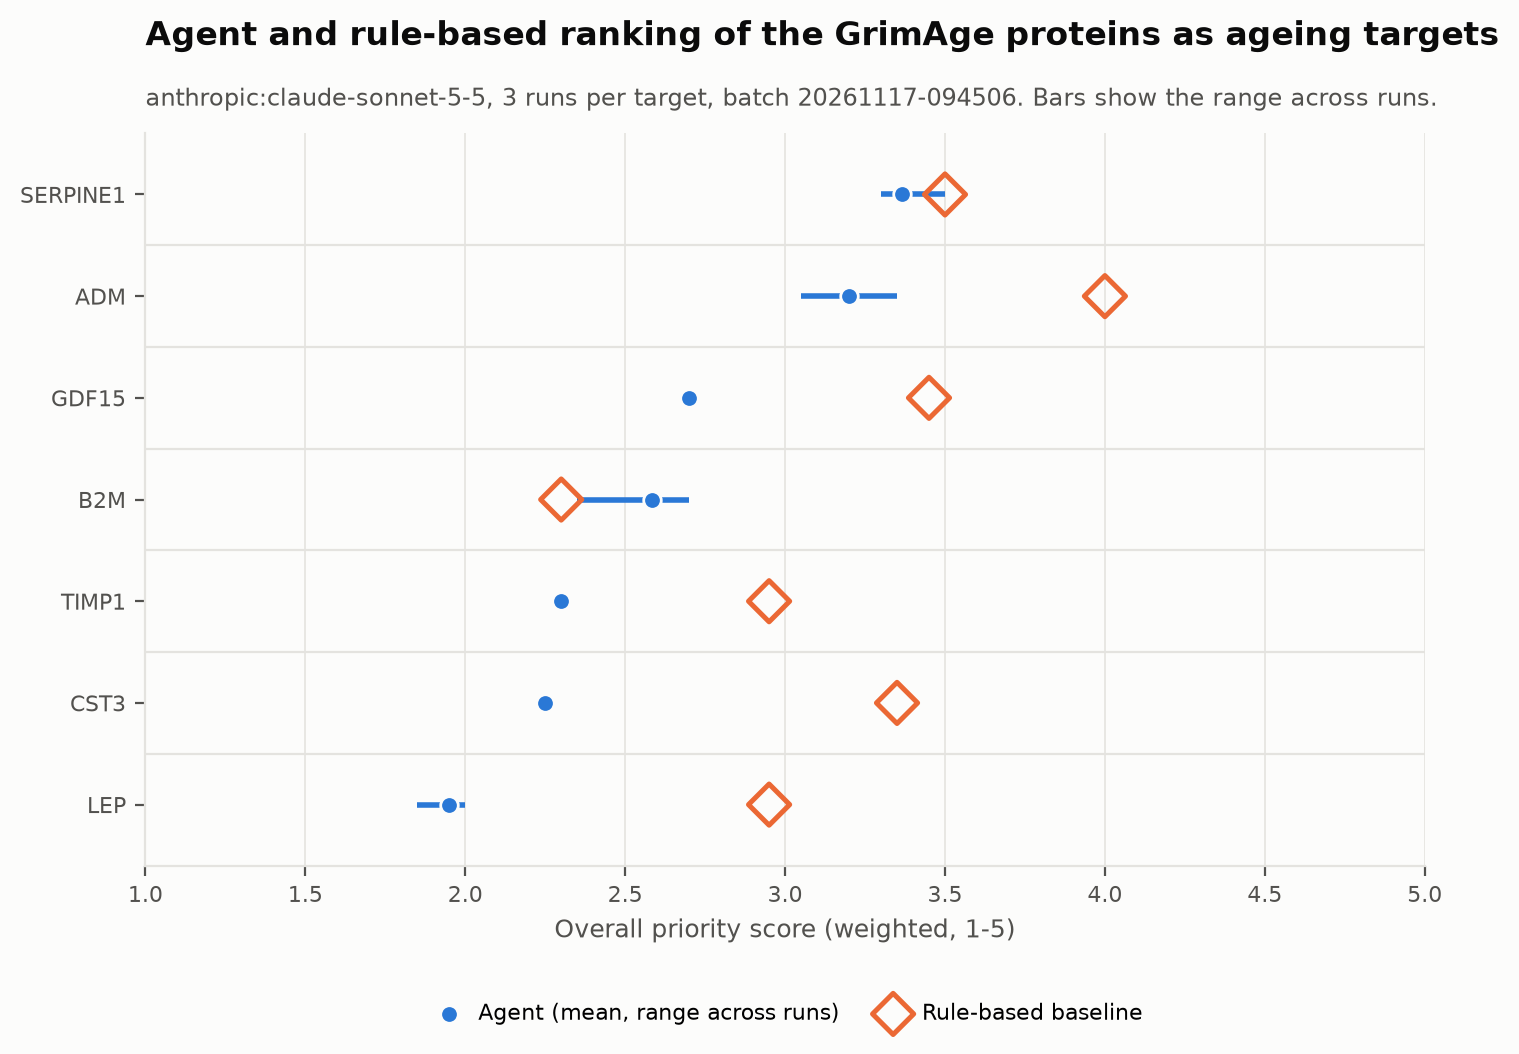

In [4]:
display(pd.read_csv(T / "ranking.csv", index_col=0).round(2))
print("Agent vs baseline, per dimension:")
display(pd.read_csv(T / "agreement.csv", index_col=0).round(2))
display(Image(filename=T / "ranking.png", width=700))

## 4. How much the ranking depends on the weights

The ranking recomputed for 20,000 random weightings: each weight within about ±0.05 of the chosen value, and every possible weighting.

In [5]:
weights = pd.read_csv(T / "weight_sensitivity.csv", index_col=[0, 1])
display(weights.round(3))

scores = mean_scores(agent.load_results(batches()[-1]))
top = weights.loc["near chosen weights"].sort_values("rank").index[:2]
diff = (scores.loc[top[0]] - scores.loc[top[1]]).rename(f"{top[0]} minus {top[1]}")
display(diff.round(2).to_frame().T)
for label, conc in [("near chosen weights", 50.0), ("any weighting", None)]:
    w = checks.sample_weights(concentration=conc)[list(DIMENSIONS)]
    print(f"{label}: {top[0]} above {top[1]} in {((w @ diff) > 0).mean():.0%} of draws")

overall  rank  p_first  p_top3  median_rank  rank_5pct  rank_95pct
weights             target                                                                      
near chosen weights SERPINE1     3.37     1    0.888   1.000          1.0        1.0         2.0
                    ADM          3.20     2    0.112   1.000          2.0        1.0         2.0
                    GDF15        2.70     3    0.000   1.000          3.0        3.0         3.0
                    B2M          2.58     4    0.000   0.000          4.0        4.0         4.0
                    TIMP1        2.30     5    0.000   0.000          5.0        5.0         6.0
                    CST3         2.25     6    0.000   0.000          6.0        5.0         6.0
                    LEP          1.95     7    0.000   0.000          7.0        7.0         7.0
any weighting       SERPINE1     3.37     1    0.564   0.990          1.0        1.0         2.0
                    ADM          3.20     2    0.436   0.995          2.0        1.0         2.0
                    GDF15        2.70     3    0.001   1.000          3.0        2.0         3.0
                    B2M          2.58     4    0.000   0.000          4.0        4.0         5.0
                    TIMP1        2.30     5    0.000   0.005          5.0        4.0         6.0
                    CST3         2.25     6    0.000   0.010          6.0        4.0         7.0
                    LEP          1.95     7    0.000   0.000          7.0        6.0         7.0

dimension,ageing_relevance,mechanism,tractability,safety,clinical_precedence
SERPINE1 minus ADM,1.0,1.33,0.0,-0.67,-1.33


near chosen weights: SERPINE1 above ADM in 89% of draws
any weighting: SERPINE1 above ADM in 56% of draws


## 5. Earlier prompt versions

The same evidence assessed with the version 1 and version 2 prompts (`results/targets/rebuilt/`); see `docs/development-notes.md` for what changed and why.

In [6]:
versions = {"v1": T / "rebuilt" / "20261116-215422", "v2": T / "rebuilt" / "20261116-230637", "v3 (with MR)": T}
pd.concat({v: pd.read_csv(p / "ranking.csv", index_col=0)[["agent_overall", "recommendation_counts"]]
           for v, p in versions.items()}, axis=1).round(2)

v1                                        v2                              v3 (with MR)                            
         agent_overall       recommendation_counts agent_overall       recommendation_counts agent_overall       recommendation_counts
SERPINE1          3.50    prioritise 2, consider 1          3.37                  consider 3          3.37    prioritise 2, consider 1
ADM               3.30                  consider 3          3.10                  consider 3          3.20                  consider 3
GDF15             3.00                  consider 3          2.70                  consider 3          2.70                  consider 3
CST3              2.88  consider 2, deprioritise 1          2.85  deprioritise 2, consider 1          2.25              deprioritise 3
B2M               2.50                  consider 3          2.70                  consider 3          2.58                  consider 3
TIMP1             2.33              deprioritise 3          2.50  deprioritise 2, consider 1          2.30  deprioritise 2, consider 1
LEP               2.30  consider 2, deprioritise 1          2.30              deprioritise 3          1.95              deprioritise 3